In [2]:
import os
import tensorflow as tf
import keras
from keras import layers, models

DATASET_PATH = "chetankv/dogs-cats-images"

In [3]:
!kaggle datasets download -d {DATASET_PATH}

Dataset URL: https://www.kaggle.com/datasets/chetankv/dogs-cats-images
License(s): CC0-1.0
100% 435M/435M [00:03<00:00, 138MB/s]



In [4]:
import zipfile
zip_file_name = DATASET_PATH.split('/')[-1] + ".zip"

if os.path.exists(zip_file_name):
    with zipfile.ZipFile(zip_file_name, 'r') as zip_ref:
        zip_ref.extractall("/content/dataset")
    print("Dataset successfully downloaded and unzipped into /content/dataset")
    # Clean up the zip file to save space
    os.remove(zip_file_name)
else:
    print("Download failed. Please check your Kaggle path.")

Dataset successfully downloaded and unzipped into /content/dataset


In [5]:
DATA_DIR = "/content/dataset/dataset"
IMG_SIZE = (224, 224)
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

In [6]:
train_ds = keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/training_set",
    seed=1,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = keras.utils.image_dataset_from_directory(
    f"{DATA_DIR}/test_set",
    seed=1,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

Found 8000 files belonging to 2 classes.
Found 2000 files belonging to 2 classes.


In [7]:
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [8]:
from keras.applications.vgg16 import VGG16, preprocess_input

base_model = VGG16(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [9]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
model = models.Sequential([
    layers.Input(shape = (224, 224, 3)),
    layers.Lambda(preprocess_input), # Scale : 0-255 -> 0-1
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

# Feature Extraction : Training Only Classification Head

In [11]:
model.compile(
    optimizer='adam',
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    batch_size=BATCH_SIZE
)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 438ms/step - accuracy: 0.9467 - loss: 0.1924 - val_accuracy: 0.9800 - val_loss: 0.0759
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 38s 304ms/step - accuracy: 0.9794 - loss: 0.0599 - val_accuracy: 0.9785 - val_loss: 0.0682
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 39s 312ms/step - accuracy: 0.9881 - loss: 0.0319 - val_accuracy: 0.9785 - val_loss: 0.0770
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 41s 325ms/step - accuracy: 0.9916 - loss: 0.0231 - val_accuracy: 0.9770 - val_loss: 0.0802
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 42s 333ms/step - accuracy: 0.9940 - loss: 0.0180 - val_accuracy: 0.9770 - val_loss: 0.0793


## Fine-Tuning Phase
We will now unfreeze the last convolutional block of VGG16 (which corresponds to `block5_conv1`, `block5_conv2`, `block5_conv3`, and the pooling layer) to allow the model to adjust high-level features for this specific dataset. We'll use a very low learning rate (`1e-5`) to avoid destroying the pre-trained weights.

In [12]:
# Unfreeze the base model
base_model.trainable = True

# Freeze all layers except the last block (block5)
# VGG16 has 19 layers (including input/pooling). We can freeze up to 'block5_conv1'
for layer in base_model.layers:
    if 'block5' in layer.name:
        layer.trainable = True
    else:
        layer.trainable = False

# Verify trainable status
for i, layer in enumerate(base_model.layers):
    print(f"{i}: {layer.name} - Trainable: {layer.trainable}")

# Compile the model with a very low learning rate
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Summary to show the updated trainable parameters count
model.summary()

0: input_layer - Trainable: False
1: block1_conv1 - Trainable: False
2: block1_conv2 - Trainable: False
3: block1_pool - Trainable: False
4: block2_conv1 - Trainable: False
5: block2_conv2 - Trainable: False
6: block2_pool - Trainable: False
7: block3_conv1 - Trainable: False
8: block3_conv2 - Trainable: False
9: block3_conv3 - Trainable: False
10: block3_pool - Trainable: False
11: block4_conv1 - Trainable: False
12: block4_conv2 - Trainable: False
13: block4_conv3 - Trainable: False
14: block4_pool - Trainable: False
15: block5_conv1 - Trainable: True
16: block5_conv2 - Trainable: True
17: block5_conv3 - Trainable: True
18: block5_pool - Trainable: True


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 7,145,217 (27.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [13]:
# Fine-tune the model for 5 epochs
history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 51s 356ms/step - accuracy: 0.9955 - loss: 0.0138 - val_accuracy: 0.9800 - val_loss: 0.0682
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 45s 359ms/step - accuracy: 0.9964 - loss: 0.0115 - val_accuracy: 0.9850 - val_loss: 0.0685
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 46s 371ms/step - accuracy: 0.9991 - loss: 0.0036 - val_accuracy: 0.9860 - val_loss: 0.0694
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 47s 376ms/step - accuracy: 0.9989 - loss: 0.0032 - val_accuracy: 0.9875 - val_loss: 0.0614
Epoch 5/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 49s 392ms/step - accuracy: 0.9999 - loss: 0.0013 - val_accuracy: 0.9880 - val_loss: 0.0660


## Visualizing Accuracy Across Both Phases
Let's concatenate the training metrics from both Phase 1 (Feature Extraction) and Phase 2 (Fine-Tuning) to plot the performance trend.

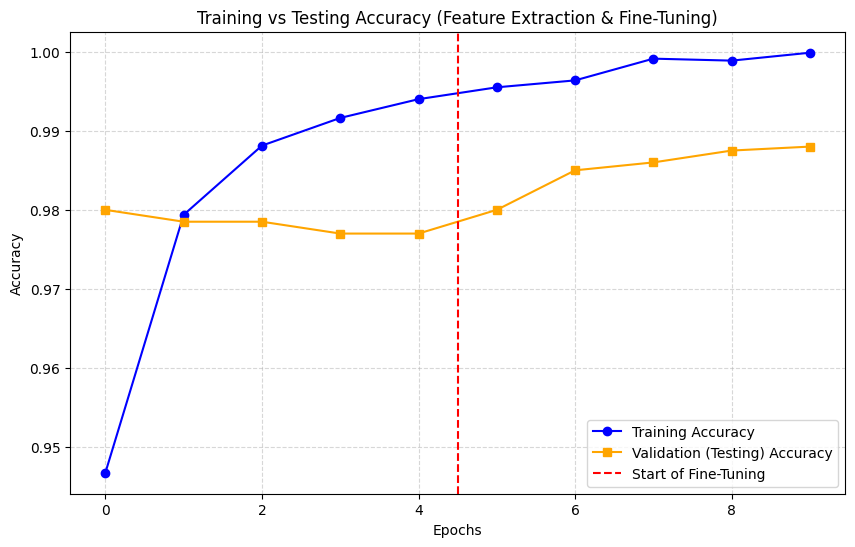

In [14]:
import matplotlib.pyplot as plt

# Retrieve metrics
acc_phase1 = history_phase1.history['accuracy']
val_acc_phase1 = history_phase1.history['val_accuracy']

acc_phase2 = history_phase2.history['accuracy']
val_acc_phase2 = history_phase2.history['val_accuracy']

# Combine metrics
total_acc = acc_phase1 + acc_phase2
total_val_acc = val_acc_phase1 + val_acc_phase2

# Plot configuration
plt.figure(figsize=(10, 6))
plt.plot(total_acc, label='Training Accuracy', color='blue', marker='o')
plt.plot(total_val_acc, label='Validation (Testing) Accuracy', color='orange', marker='s')

# Draw a vertical line to mark the transition to fine-tuning
plt.axvline(x=len(acc_phase1) - 0.5, color='red', linestyle='--', label='Start of Fine-Tuning')

plt.title('Training vs Testing Accuracy (Feature Extraction & Fine-Tuning)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()